In [1]:
import numba

In [2]:
import math
import random
import numpy as np

def randn(*n):
    return np.random.randn(*n) * 2 - 1
    # return [random.random() * 2 - 1 for _ in range(n)]


In [3]:
w, h = 2, 2
s = 3
k = 2

# w, h = 28, 28
# s = 300
# k = 10

In [4]:
wh = w * h

# Forward

In [5]:
X = randn(wh)
X

array([-1.52320762, -0.71838407,  0.07717309,  1.13797814])

In [6]:
# layer_hidden_weights = [randn(wh) for _ in range(s)]
layer_hidden_weights = randn(s, wh)
layer_hidden_bias = randn(s)


# @numba.jit()
def relu_forward(x: float):
    return max(0.0, x)

# @numba.jit()
def layer_hidden_forward(x):
    y = [0.0] * s
    for i in range(s):
        u = 0.0

        for j in range(wh):
            u += x[j] * layer_hidden_weights[i][j]
        u += layer_hidden_bias[i]

        # NOTE: 
        # we may separate passes and run relu on whole `y` vector. 
        #   like `y = relu_forward(y)`
        # but it looks like overcomplication for now
        y[i] = relu_forward(u)

    return y

In [7]:
H = layer_hidden_forward(X)
H

[np.float64(5.5583600027065545), 0.0, 0.0]

In [8]:

# layer_output_weights = [randn(s) for _ in range(k)]
layer_output_weights = randn(k, s)
layer_output_bias = randn(k)

# @numba.jit()
def softmax_forward(x):
    y = [0.0] * k

    e_max = max(x)
    e_sum = 0
    for i in range(k):
        e_sum += math.exp(x[i] - e_max)
    
    for i in range(k):
        e = math.exp(x[i] - e_max)
        y[i] = e / e_sum

    return y

# @numba.jit()
def layer_output_forward(x):
    y = [0.0] * k
    for i in range(k):
        u = 0

        for j in range(s):
            u += x[j] * layer_output_weights[i][j]
        u += layer_output_bias[i]

        y[i] = u

    return y

In [9]:
O = layer_output_forward(H)
O

[np.float64(-13.95105422394193), np.float64(-6.420151265194553)]

In [10]:
softmax_forward(O)

[0.0005359664088905657, 0.9994640335911094]

In [11]:
# Y = [0.0] * k
Y = np.zeros(k)
Y[random.randint(0, k-1)] = 1.0

# @numba.jit()
def layer_loss_forward(x, y):
    x = softmax_forward(x)

    err_sum = 0.0
    for i in range(k):
        # math.log(x[i]) `ValueError: math domain error` when `x[i] == 0.0`
        if x[i] == 0.0:
            if y[i] == 0.0:
                v = 0.0
            else:
                v = -np.inf
        else:
            v = y[i] * math.log(x[i])

        err_sum += v

    return -err_sum

In [12]:
E = layer_loss_forward(
    O, Y
)
E, Y

(np.float64(0.0005361100902275791), array([0., 1.]))

In [13]:
layer_loss_forward(
    layer_output_forward(
        layer_hidden_forward(X)
    ),
    Y
)


np.float64(0.0005361100902275791)

# Backward

In [14]:
import torch


In [15]:
a = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(2.0, requires_grad=True)

f = a ** 2 * b
f.backward()

a.grad == (2 * 3 * 2), b.grad == (3 ** 2)

(tensor(True), tensor(True))

In [16]:
layer_hidden_weights

array([[-1.90716622, -3.43736481, -1.43031105, -0.08518709],
       [-0.94256407, -0.18667967,  0.71987527, -2.16945255],
       [-1.5026271 , -1.7093385 , -2.67073875, -1.80397989]])

In [17]:
layer_output_weights_t = torch.tensor(layer_output_weights, requires_grad=True)
layer_output_bias_t = torch.tensor(layer_output_bias, requires_grad=True)

x = torch.ones(s) * 2 

u = 0.0

for j in range(s):
    u += x[j] * layer_output_weights_t[0][j]
u += layer_output_bias_t[0]

u.backward()


In [18]:
layer_output_bias_t.grad

tensor([1., 0.], dtype=torch.float64)

In [19]:
layer_output_weights_t.grad

tensor([[2., 2., 2.],
        [0., 0., 0.]], dtype=torch.float64)

In [20]:
torch.manual_seed(0)
v = torch.ones(s, requires_grad=True)
v = torch.rand(s, requires_grad=True)

y = torch.zeros(s)
y[0] = 1.0
y = torch.rand(s)

e = v.exp()
sm = e.sum()
u = e / sm

m = y * torch.log(u)
L = - (m.sum())

L.backward()

# u, m, y, L

In [21]:
v.grad

tensor([ 0.2285,  0.1658, -0.3943])

In [22]:
u * y.sum() - y # dL/dv

tensor([ 0.2285,  0.1658, -0.3943], grad_fn=<SubBackward0>)

In [23]:
torch.manual_seed(0)
layer_output_weights_t = torch.rand((k, s), requires_grad=True)
layer_output_bias_t = torch.rand((k), requires_grad=True)

x = torch.ones(s)
x = torch.rand(s)


v_elements = []

for i in range(k):
    v_i = 0 
    for j in range(s):
        v_i += x[j] * layer_output_weights_t[i][j]
    v_i += layer_output_bias_t[i]

    v_elements.append(v_i)

v = torch.stack(v_elements)

# v = torch.mv(layer_output_weights_t, x) + layer_output_bias_t
v.retain_grad()


e = v.exp()
sm = e.sum()
u = e / sm

y = torch.zeros(k)
y[0] = 1.0
y = torch.rand(k)

m = y * torch.log(u)
L = - (m.sum())

L.backward()

u, m, y, L

(tensor([0.4652, 0.5348], grad_fn=<DivBackward0>),
 tensor([-0.3074, -0.0140], grad_fn=<MulBackward0>),
 tensor([0.4017, 0.0223]),
 tensor(0.3214, grad_fn=<NegBackward0>))

In [24]:
layer_output_weights_t.grad, layer_output_bias_t.grad

(tensor([[-0.0932, -0.1293, -0.0713],
         [ 0.0932,  0.1293,  0.0713]]),
 tensor([-0.2044,  0.2044]))

In [25]:
torch.outer(
    u * y.sum() - y, x
) # dL/dw_o


tensor([[-0.0932, -0.1293, -0.0713],
        [ 0.0932,  0.1293,  0.0713]], grad_fn=<MulBackward0>)

In [26]:
u * y.sum() - y # dL/db_o

tensor([-0.2044,  0.2044], grad_fn=<SubBackward0>)

In [27]:
v.grad

tensor([-0.2044,  0.2044])

In [28]:
torch.manual_seed(4)

layer_hidden_weights_t = torch.normal(0, 0.35, (s, wh), requires_grad=True)
layer_hidden_bias_t = torch.normal(0.01, 0.05, (s, ), requires_grad=True)


x = torch.rand(wh)

p_elements = []
for i in range(s):
    u = 0.0

    for j in range(wh):
        u += x[j] * layer_hidden_weights_t[i][j]
    u += layer_hidden_bias_t[i]

    p_elements.append(u)

p = torch.stack(p_elements)
p.retain_grad()


layer_output_weights_t = torch.rand((k, s), requires_grad=True)
layer_output_bias_t = torch.rand((k), requires_grad=True)

# h = torch.ones(s)
# h = torch.rand(s)

h_elements = []
for i in range(s):
    p_ = max(torch.tensor(0.0, requires_grad=True), p[i])
    h_elements.append(p_)
h = torch.stack(h_elements)
h.retain_grad()


v_elements = []
for i in range(k):
    v_i = 0 
    for j in range(s):
        v_i += h[j] * layer_output_weights_t[i][j]
    v_i += layer_output_bias_t[i]

    v_elements.append(v_i)

v = torch.stack(v_elements)

# v = torch.mv(layer_output_weights_t, x) + layer_output_bias_t
v.retain_grad()


e = v.exp()
sm = e.sum()
u = e / sm

y = torch.zeros(k)
y[0] = 1.0
y = torch.rand(k)

m = y * torch.log(u)
L = - (m.sum())

L.backward()

u, m, y, L

(tensor([0.6320, 0.3680], grad_fn=<DivBackward0>),
 tensor([-0.1350, -0.9208], grad_fn=<MulBackward0>),
 tensor([0.2943, 0.9210]),
 tensor(1.0558, grad_fn=<NegBackward0>))

In [29]:
layer_output_weights_t.grad, layer_output_bias_t.grad

(tensor([[ 0.3419,  0.0000,  0.3239],
         [-0.3419,  0.0000, -0.3239]]),
 tensor([ 0.4738, -0.4738]))

In [30]:
# dL/dw_o
torch.outer(
    u * y.sum() - y, h
), u * y.sum() - y # dL/db_o

(tensor([[ 0.3419,  0.0000,  0.3239],
         [-0.3419, -0.0000, -0.3239]], grad_fn=<MulBackward0>),
 tensor([ 0.4738, -0.4738], grad_fn=<SubBackward0>))

In [31]:
h.grad

tensor([-0.1549,  0.0893,  0.0156])

In [32]:
# (u * y.sum() - y) @ layer_output_weights_t # dL/dh
v.grad @ layer_output_weights_t # dL/dh

tensor([-0.1549,  0.0893,  0.0156], grad_fn=<SqueezeBackward4>)

In [33]:
p

tensor([ 0.7216, -0.3860,  0.6837], grad_fn=<StackBackward0>)

In [34]:
p.grad 

tensor([-0.1549,  0.0000,  0.0156])

In [35]:
(v.grad @ layer_output_weights_t) * (p > 0) # dL/dp

tensor([-0.1549,  0.0000,  0.0156], grad_fn=<MulBackward0>)

In [36]:
layer_hidden_bias_t.grad

tensor([-0.1549,  0.0000,  0.0156])

In [37]:
p.grad # dL/db_h

tensor([-0.1549,  0.0000,  0.0156])

In [38]:
layer_hidden_weights_t.grad

tensor([[-0.0465, -0.1249, -0.1490, -0.0337],
        [ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0047,  0.0125,  0.0150,  0.0034]])

In [39]:
torch.outer(
    p.grad, x
) # dL/dw_h

tensor([[-0.0465, -0.1249, -0.1490, -0.0337],
        [ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0047,  0.0125,  0.0150,  0.0034]])

In [40]:
p.grad

tensor([-0.1549,  0.0000,  0.0156])

In [41]:
torch.manual_seed(4)

layer_hidden_weights_t = torch.normal(0, 0.35, (s, wh), requires_grad=True)
layer_hidden_bias_t = torch.normal(0.01, 0.05, (s, ), requires_grad=True)
layer_output_weights_t = torch.rand((k, s), requires_grad=True)
layer_output_bias_t = torch.rand((k), requires_grad=True)


memo = {}

L_ = 2
L = torch.tensor(0.0, requires_grad=True)
for img in range(L_):
    x = torch.rand(wh)
    # y = torch.zeros(k)
    # y[0] = 1.0
    y = torch.rand(k)


    p_elements = []
    for i in range(s):
        u_i = 0.0

        for j in range(wh):
            u_i += x[j] * layer_hidden_weights_t[i][j]
        u_i += layer_hidden_bias_t[i]

        p_elements.append(u_i)
    p = torch.stack(p_elements)
    p.retain_grad()


    h_elements = []
    for i in range(s):
        p_ = max(torch.tensor(0.0, requires_grad=True), p[i])

        h_elements.append(p_)
    h = torch.stack(h_elements)
    h.retain_grad()


    v_elements = []
    for i in range(k):
        v_i = 0

        for j in range(s):
            v_i += h[j] * layer_output_weights_t[i][j]
        v_i += layer_output_bias_t[i]

        v_elements.append(v_i)
    v = torch.stack(v_elements)
    v.retain_grad()


    e = v.exp()
    sm = e.sum()
    u = e / sm


    m = y * torch.log(u)
    L = L - (m.sum())

    # memo
    memo[img] = x, p, h, v, u, y


L = L / L_

L.backward()

In [42]:
layer_hidden_weights_t.grad, layer_hidden_bias_t.grad, layer_output_weights_t.grad, layer_output_bias_t.grad

(tensor([[0.0269, 0.0209, 0.0234, 0.0226],
         [0.0907, 0.0313, 0.0389, 0.1161],
         [0.0388, 0.0302, 0.0339, 0.0326]]),
 tensor([0.0376, 0.1178, 0.0544]),
 tensor([[ 0.1430,  0.1047,  0.3978],
         [-0.1430, -0.1047, -0.3978]]),
 tensor([ 0.4524, -0.4524]))

In [43]:
dLdb_h = 0
dLdw_h = 0
dLdb_o = 0
dLdw_o = 0

for img in range(L_):
    x, p, h, v, u, y = memo[img]

    dLdv = u * y.sum() - y
    dLdp = (dLdv @ layer_output_weights_t) * (p > 0)

    dLdb_h += dLdp
    # dLdw_h += torch.outer(dLdp, x)
    dLdw_h += dLdp.view(-1, 1) @ x.view(1, -1)
    dLdb_o += dLdv
    # dLdw_o += torch.outer(dLdv, h)
    dLdw_o += dLdv.view(-1, 1) @ h.view(1, -1)


dLdw_h / L_, dLdb_h / L_, dLdw_o / L_, dLdb_o / L_

(tensor([[0.0269, 0.0209, 0.0234, 0.0226],
         [0.0907, 0.0313, 0.0389, 0.1161],
         [0.0388, 0.0302, 0.0339, 0.0326]], grad_fn=<DivBackward0>),
 tensor([0.0376, 0.1178, 0.0544], grad_fn=<DivBackward0>),
 tensor([[ 0.1430,  0.1047,  0.3978],
         [-0.1430, -0.1047, -0.3978]], grad_fn=<DivBackward0>),
 tensor([ 0.4524, -0.4524], grad_fn=<DivBackward0>))

# Training on MNIST

In [44]:
w, h = 28, 28
wh = w * h
s = 300
k = 10

import matplotlib.pyplot as plt

DATA = "data/MNIST/raw/"


def load_images(path):
    with open(path, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, wh)


def load_labels(path):
    with open(path, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=8)


X_train = load_images(DATA + "train-images-idx3-ubyte").astype(np.float32) / 255
y_train = load_labels(DATA + "train-labels-idx1-ubyte")
X_test = load_images(DATA + "t10k-images-idx3-ubyte").astype(np.float32) / 255
y_test = load_labels(DATA + "t10k-labels-idx1-ubyte")
Y_train = np.eye(k, dtype=np.float32)[y_train]

print(f"train: {X_train.shape}, {y_train.shape}, test: {X_test.shape}, {y_test.shape}")

train: (60000, 784), (60000,), test: (10000, 784), (10000,)


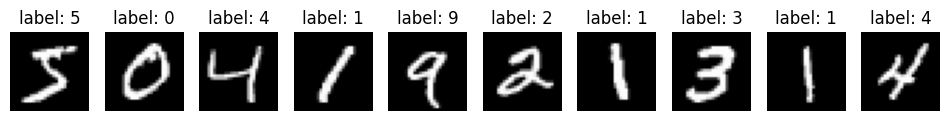

In [45]:
plt.figure(figsize=(12, 1.6))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"label: {y_train[i]}")
    plt.axis("off")
plt.show()

In [46]:
def init_params(rng):
    # nn.init.xavier_normal_(w, gain=nn.init.calculate_gain("relu"))

    # W1 = (rng.standard_normal((wh, s)) * np.sqrt(2.0 / wh)).astype(np.float32)
    W1 = (rng.normal(0, (np.sqrt(2) * np.sqrt(2 / (wh + s))) ** 2, (wh, s))).astype(
        np.float32
    )
    b1 = np.zeros(s, np.float32)
    # W2 = (rng.standard_normal((s, k)) * np.sqrt(2.0 / s)).astype(np.float32)
    W2 = (rng.normal(0, (np.sqrt(2) * np.sqrt(2 / (s + k))) ** 2, (s, k))).astype(
        np.float32
    )
    b2 = np.zeros(k, np.float32)
    return W1, b1, W2, b2


def forward(x):
    p = x @ W1 + b1

    h = np.maximum(p, 0)

    v = h @ W2 + b2

    e = np.exp(v - v.max(axis=1, keepdims=True))
    u = e / e.sum(axis=1, keepdims=True)

    return p, h, u


def update(x, y):
    n = len(x)
    p, h, u = forward(x)

    # dv = (u * y.sum(axis=1, keepdims=True) - y) / n
    # y.sum(axis=1, keepdims=True) = 1 for MNIST
    dv = (u - y) / n
    dp = (dv @ W2.T) * (p > 0)

    dW1 = x.T @ dp
    db1 = dp.sum(axis=0)
    dW2 = h.T @ dv
    db2 = dv.sum(axis=0)

    return dW1, db1, dW2, db2

In [47]:
%%time

lr = 0.1
batch_size = 32
epochs = 20

rng = np.random.default_rng(0)
W1, b1, W2, b2 = init_params(rng)

for epoch in range(epochs):
    perm = rng.permutation(len(X_train))

    for i in range(0, len(perm), batch_size):
        idx = perm[i : i + batch_size]
        dW1, db1, dW2, db2 = update(X_train[idx], Y_train[idx])
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    u_train = forward(X_train)[2]
    y_logu = np.log(u_train[np.arange(len(y_train)), y_train])
    loss = -y_logu.mean()

    err = (u_train.argmax(axis=1) != y_train).mean()
    print(f"Epoch {epoch+1:2d}/{epochs}: {loss=:.4f} train {err=:.4%}")

Epoch  1/20: loss=0.2107 train err=6.0150%
Epoch  2/20: loss=0.1198 train err=3.3717%
Epoch  3/20: loss=0.0876 train err=2.4917%
Epoch  4/20: loss=0.0702 train err=1.9783%
Epoch  5/20: loss=0.0575 train err=1.6067%
Epoch  6/20: loss=0.0506 train err=1.4600%
Epoch  7/20: loss=0.0366 train err=0.9100%
Epoch  8/20: loss=0.0356 train err=1.0050%
Epoch  9/20: loss=0.0275 train err=0.6400%
Epoch 10/20: loss=0.0282 train err=0.7233%
Epoch 11/20: loss=0.0219 train err=0.4750%
Epoch 12/20: loss=0.0177 train err=0.3483%
Epoch 13/20: loss=0.0146 train err=0.2283%
Epoch 14/20: loss=0.0123 train err=0.1633%
Epoch 15/20: loss=0.0132 train err=0.2350%
Epoch 16/20: loss=0.0099 train err=0.1117%
Epoch 17/20: loss=0.0089 train err=0.0950%
Epoch 18/20: loss=0.0075 train err=0.0667%
Epoch 19/20: loss=0.0065 train err=0.0433%
Epoch 20/20: loss=0.0063 train err=0.0367%
CPU times: total: 1min 34s
Wall time: 20.6 s


In [48]:
u_test = forward(X_test)[2]
y_pred = u_test.argmax(axis=1)
test_error = (y_pred != y_test).mean()
print(f"Test error: {test_error:.4%}, test accuracy: {1 - test_error:.4%}")

Test error: 1.7900%, test accuracy: 98.2100%
